# Frequency, severity and pure premium models: summary

This is the short version of `03_glm.ipynb`. It loads the tables and charts that the full notebook saved in
`outputs/m3_draft/`, and it never fits a model, so it runs in seconds. The full notebook has the evidence for every
decision, and the diagrams of the data flow and the decision rules are in [_docs/data-flow.md](../_docs/data-flow.md).

**The problem.** A pricing reviewer wants to see how the pure premium of a UK-style individual private medical insurance
(PMI) policy can be built from claims experience, and how far each modelling choice can be trusted. The pure premium is the
expected claims cost of a person for a year of cover, before expenses, margin and tax. It is built from a frequency model (the
chance of a claim) and a severity model (the cost of a claim).

**Data and UK framing.** The data are the Medical Expenditure Panel Survey (MEPS) of the US Agency for Healthcare Research and
Quality, for 2022 and 2023, with PMI-scope claims at 2023 prices. The 2022 rows are split by household into a train split and
a test split that is held out, and 2023 is kept for a later out-of-time test. MEPS is US data, so it gives the shape of cost
and not UK levels. Only factors a UK insurer could use price the policy. Sex, race, income and education are excluded, and
US-specific or non-UK variables are analysis-only. All figures are aggregates.

## Key decisions and findings

Each decision below was made by the user, at a decision gate where one applied, on the evidence in the section named. The last column names the
entry in `_docs/decisions.md` that records it.

| Decision or finding | Choice | Why | Section | Entry in `_docs/decisions.md` |
|---|---|---|---|---|
| Modelling frame | 2022 split by household into train and test, with 2023 held out | The yardstick is a holdout with no household on both sides | [Data and metrics](03_glm.ipynb#data-and-metrics) | Household-grouped split within 2022 |
| Benefit types | Inpatient and day-case against outpatient, using the surgical-procedure flag | A UK policy prices these separately, and the flag is the only direct indicator | [Benefit types](03_glm.ipynb#benefit-types) | Benefit types for the stacked candidate |
| Level grouping | Five-year age bands, thin and placeholder levels merged into the reference | Stable relativities, with at least 100 claimants in every age band | [Rating-factor levels](03_glm.ipynb#rating-factor-levels-decision-gate-6) | Rating-factor level grouping |
| Large claims | Cap of 100,000 dollars per person-year, with a provisional flat load of 6.5 percent | The cap affects 32 train claimants and removes 6.1 percent of cost | [Large claims](03_glm.ipynb#large-claims-decision-gate-5) | Large-claim cap and provisional load |
| Model structure | Candidate (a), a cloglog frequency with a Gamma severity | Best on the test split at three Tweedie powers, and it survives a multiplicative form | [Model comparison](03_glm.ipynb#model-comparison) | Model structure and the surrogate model (tariff) check |
| Permitted factors | Age, region and seven condition flags price the policy | The factor rule is p below 0.05 and an AIC gain, and the flags stand in for underwriting | [Permitted rating factors](03_glm.ipynb#permitted-rating-factors-decision-gate-7-part-2) | Permitted factors and the final factor set |
| Smoking | Analysis-only, with no smoker discount | The discount is not explained by the condition flags and fits lower use of care | [Smoking check](03_glm.ipynb#smoking-check-decision-gate) | Smoking and age decisions |
| Age | Tariff band relativities read off a smooth curve, with five-year bands as the table format | Preferred in the train data, and it removes irregularities between bands | [Age curve](03_glm.ipynb#age-curve-bands-or-a-smooth-curve-decision-gate) | Smoking and age decisions |
| Rebalancing | The base rate is rescaled so that train predicted cost equals train actual cost | Analysis-only factors are priced at their reference level, which leaves the base rate too low | [Permitted rating factors](03_glm.ipynb#permitted-rating-factors-decision-gate-7-part-2) | Permitted factors and the final factor set |
| Exercise | An insight and not a rating factor | The raw gap of 31 percent disappears after adjustment | [Permitted rating factors](03_glm.ipynb#permitted-rating-factors-decision-gate-7-part-2) | Permitted factors and the final factor set |

### Headline numbers

All scores are on the 2022 test split, which has 4,151 person-years and 1,731 claimants, so small differences are within
sampling noise. The lowest deviance is best, and the highest Gini is best.

| Measure | Value |
|---|---|
| Baseline test deviance (overall mean) | 928,364 |
| Candidate (a), all factors | deviance 808,193, Gini 0.433 |
| Candidate (b), Poisson frequency | deviance 816,054 |
| Surrogate model (tariff) of (a), against (b) | deviance 814,292, Gini 0.426 |
| Final structure, 9 rating factors | deviance 830,232, Gini 0.393 |
| Final tariff, 26 parameters | deviance 838,173, Gini 0.378, A/E 1.081 (band 0.90 to 1.28) |
| Smoking relativity | daily 0.60 and occasional 0.69, and daily is 0.74 when self-rated health is also left out |
| Exercise, adjusted | frequency 0.97 and severity 1.07, both consistent with no effect |

The final rating factors are age, region and the condition flags for high blood pressure, coronary heart disease, other
heart disease, cholesterol, cancer, arthritis and asthma. Self-rated health, exercise, `inscov` and smoking are analysis-only.
The saved charts are in `outputs/m3_draft/figures/` and the saved tables are in `outputs/m3_draft/`.

### Headline numbers from the saved tables

The table below is read from the files named in its last column.

In [1]:
import pandas as pd
from IPython.display import Image

from health_pricing.models import figures, summary

pd.options.display.float_format = "{:,.3f}".format
summary.headline_numbers()

,number,value,source
0,Baseline test deviance (p = 1.5),"928,364",model_comparison.csv
1,"Candidate (a), all factors, test deviance","808,193",model_comparison.csv
2,"Candidate (a), all factors, test Gini",0.433,model_comparison.csv
3,"Candidate (b), test deviance","816,054",model_comparison.csv
4,"Surrogate model (tariff) of (a), test deviance","814,292",model_comparison.csv
5,"Surrogate model (tariff) of (a), test Gini",0.426,model_comparison.csv
6,"Final structure (9 factors), test deviance","830,232",permitted_factor_options.csv
7,"Final structure (9 factors), test Gini",0.393,permitted_factor_options.csv
8,"Final tariff, test deviance","838,173",final_scores.csv
9,"Final tariff, test Gini",0.378,final_scores.csv


## Key charts

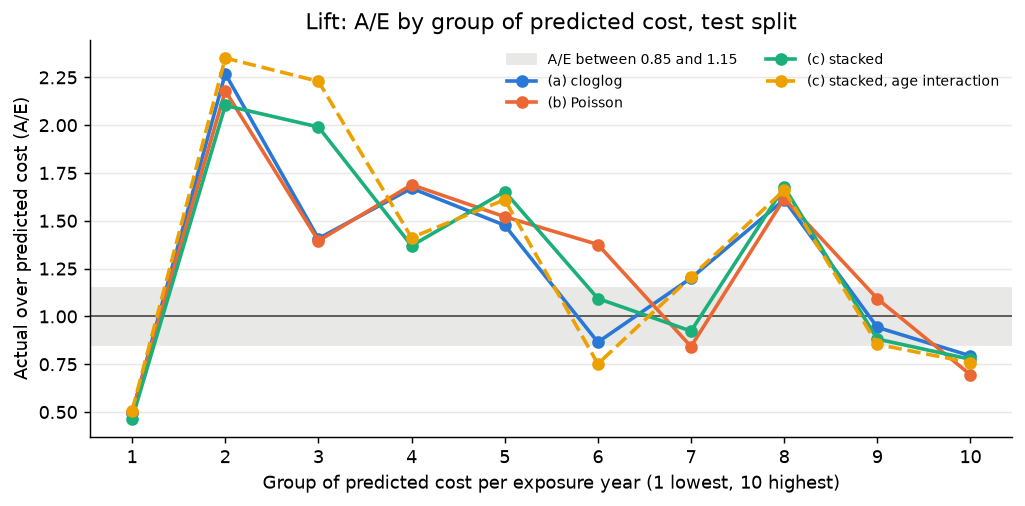

In [2]:
Image(filename=str(figures.FIGURES_DIR / "lift_candidates.png"))

**Candidates on the test split.** The chart shows A/E (actual over predicted cost) by group of predicted cost per exposure
year. The four candidates move together, with the lowest group over-predicted and some middle groups under-predicted, so the
pattern belongs to this small, heavy-tailed test split and not to one structure. Candidate (a) has a test deviance of
808,193 and a Gini of 0.433, against
928,364 for the overall mean.

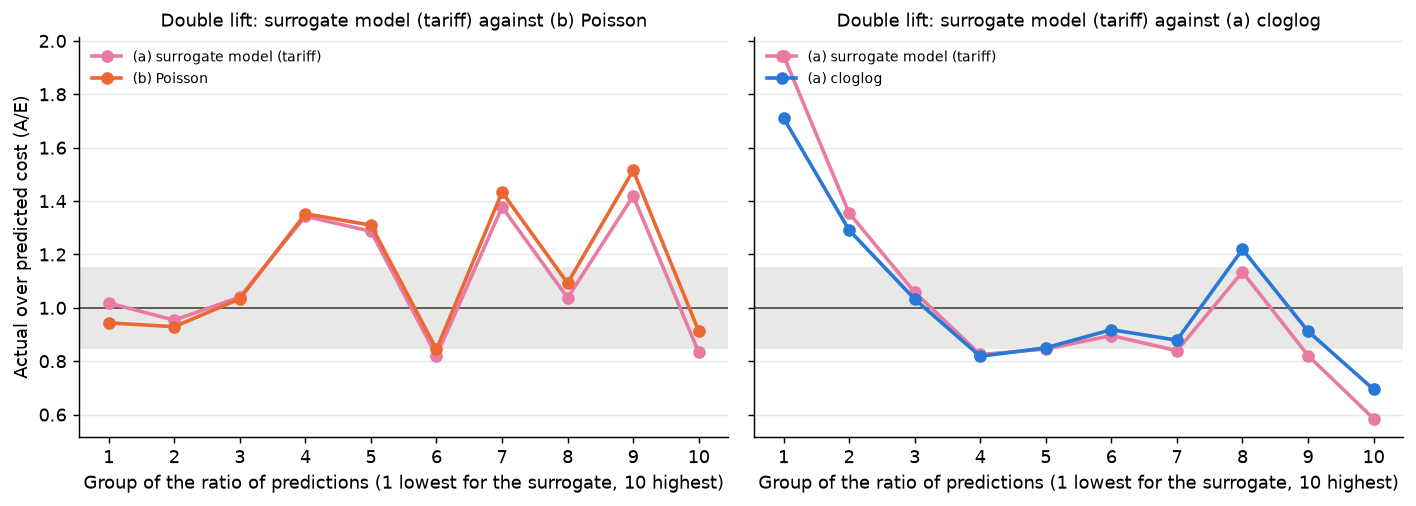

In [3]:
Image(filename=str(figures.FIGURES_DIR / "double_lift_surrogate.png"))

**Does the choice survive a multiplicative form.** A rating engine multiplies relativities, and candidate (a) is not exactly
multiplicative. The left panel compares its surrogate model (tariff), a multiplicative model fitted to (a)'s predicted cost,
with candidate (b), which is already multiplicative. The tariff has the lower deviance (814,292 against
816,054) and is nearer 1 in 7 of 10 groups, so (a) is confirmed. The margin is small and within
sampling noise.

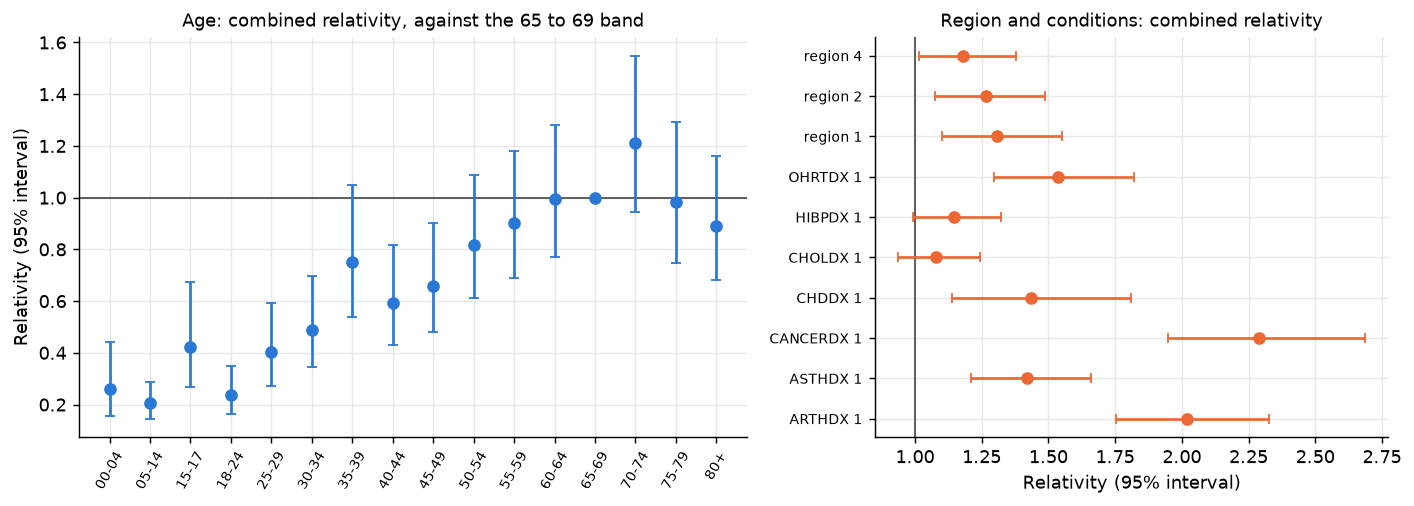

In [4]:
Image(filename=str(figures.FIGURES_DIR / "relativities_final.png"))

**Relativities of the final structure.** The final structure prices on age, region and seven condition flags. Against the 65 to 69
band, the combined age relativity is about 0.25 for ages 0 to 4 and 18 to 24 and peaks at 1.21 for ages 70 to 74, with wide
intervals. Cancer (2.29), arthritis (2.02), other heart disease (1.54), coronary heart disease (1.43) and asthma (1.42) carry
the largest condition loadings. The condition flags stand in for underwriting. The bounds on the combined relativities treat
frequency and severity as independent, so they are approximate.

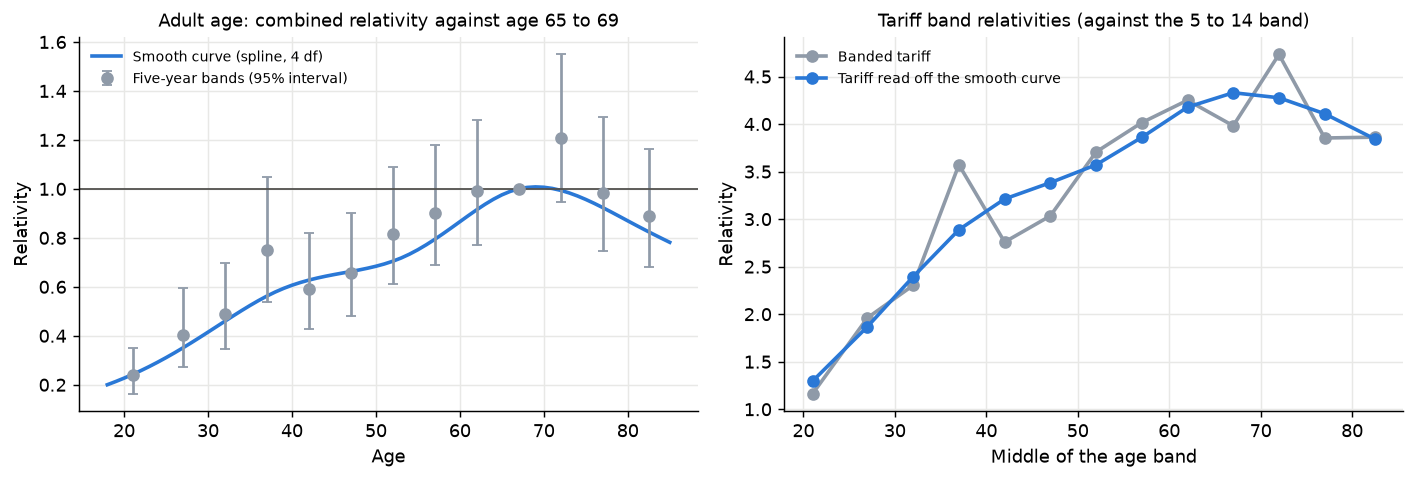

In [5]:
Image(filename=str(figures.FIGURES_DIR / "age_curve.png"))

**Smooth age curve.** A natural spline for adult age (4 degrees of freedom) has 16 fewer parameters than the five-year bands
and a lower AIC, and it adds something beyond the bands while the bands add nothing beyond it. On the test split the bands are
slightly better, which is within noise, so the preference is moderate. The tariff's band relativities are read off the smooth
curve, which removes the bumps and dips of the banded tariff, and the five-year bands stay as the table format.

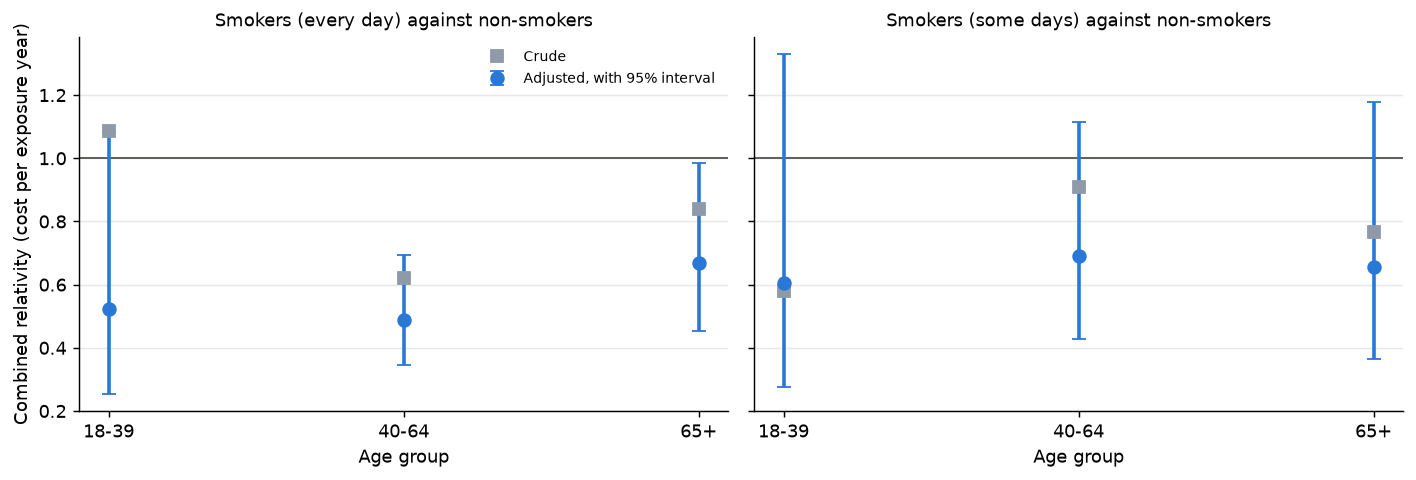

In [6]:
Image(filename=str(figures.FIGURES_DIR / "smoking_by_age_group.png"))

**Smoking.** Smokers appear cheaper than non-smokers, with a relativity of 0.60 for daily smokers and
0.69 for occasional smokers. Removing the condition flags does not change it, and leaving
out self-rated health as well raises it to only 0.74. The gap is
mostly in frequency and is already in the crude data. It fits the lower use of care seen in US survey data, and the data cannot
separate lower need from lower use. Smoking is therefore analysis-only and there is no smoker discount in the tariff.

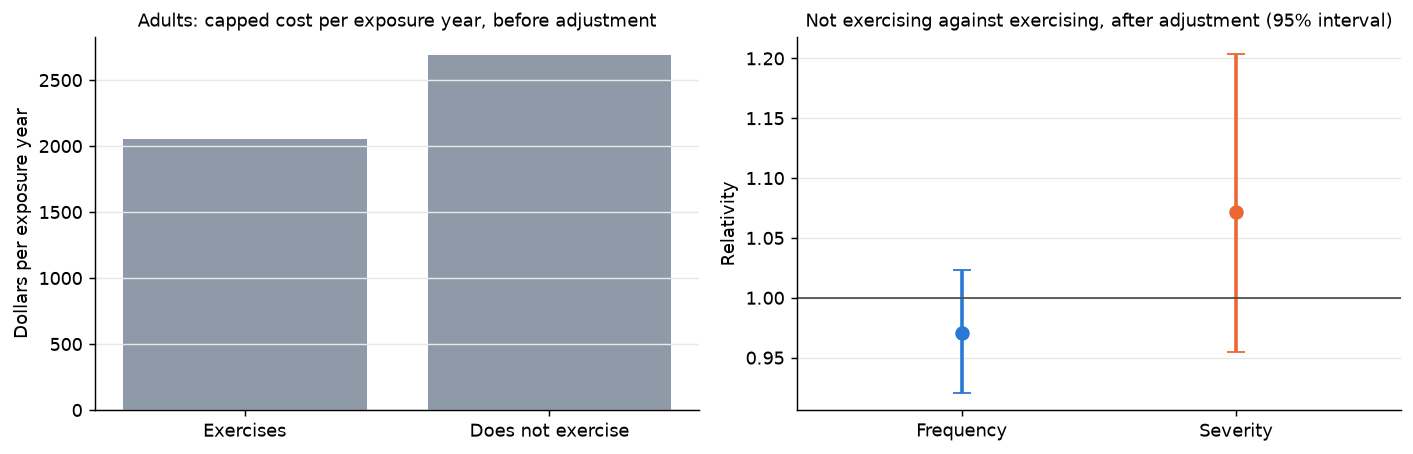

In [7]:
Image(filename=str(figures.FIGURES_DIR / "exercise_insight.png"))

**Exercise.** Adults who do not exercise cost 31 percent more per exposure year before
adjustment. After adjustment the relativities are 0.97 for frequency and
1.07 for severity, and both intervals include 1. The raw gap reflects who exercises and
not a causal effect, and estimating the effect would need a randomised design. Exercise is an insight and not a rating factor.

## Final tariff

The final tariff has five-year age bands whose relativities are read off the smooth curve, and it is exactly multiplicative.
It is rebalanced on train so that predicted cost on train equals actual cost on train. The relativities are against the
reference level of each factor, and the presentation column shows age against the 65 to 69 band.

In [8]:
tariff = summary.read("relativities_tariff.csv")
tariff[["factor", "level", "relativity", "presentation_relativity", "exposure", "claimants"]]

,factor,level,relativity,presentation_relativity,exposure,claimants
0,age,05-14,1.000,0.231,"2,002.417",368
1,age,00-04,1.301,0.300,693.250,106
2,age,15-17,1.985,0.459,634.000,150
3,age,18-24,1.296,0.299,"1,168.917",246
4,age,25-29,1.869,0.432,944.667,227
5,age,30-34,2.394,0.553,"1,019.583",302
6,age,35-39,2.889,0.667,"1,115.500",339
7,age,40-44,3.212,0.742,"1,046.167",370
8,age,45-49,3.383,0.781,994.333,386
9,age,50-54,3.571,0.825,"1,126.833",502


## Limitations

- **US data.** MEPS describes US use of care and prices. It gives the shape of cost, and the levels are not UK levels.
  Insurance cover type and access to care are US effects, and they are analysis-only.
- **A small, heavy-tailed test split.** The test split has 4,151 person-years and 1,731 claimants, with 11 above the
  large-claim cap. Differences between candidates and between factor sets are within sampling noise, and the test A/E of
  about 1.08 cannot be told from 1.00.
- **Provisional large-claim load.** The flat 6.5 percent load comes from the train split and is used for comparison only. It
  is to be re-estimated on the pooled 2022 and 2023 rows, preferably with a fitted tail distribution.
- **Conditions stand in for underwriting.** UK insurers usually exclude claims linked to pre-existing conditions, and
  modelling that needs a link from each condition to each claim. The condition loadings here overstate the loss that a
  policy with exclusions would pay.
- **Smoking.** Smokers appear cheaper in these data, which fits lower use of care and not lower need. Smoking is
  analysis-only, and any smoker loading would have to be a judgement loading from an external source.
- **Age curve.** The smooth curve is preferred in the train data and slightly worse on the test split, so the preference is
  moderate. Intervals for the combined relativities treat frequency and severity as independent, so they are approximate.
- **Tariff.** The final tariff is exactly multiplicative and departs from the banded structure by a median of 5.5 percent.
  Its relativities are point values with no interval.
- **Not yet done.** The 2023 out-of-time test, trend projection of the cap and the premium, expenses, margin and tax, and a
  gradient-boosting challenger are later work.